**Assignment no. 3: Linear Regression**

---


Scrap and create your own dataset, and Implement Simple Linear Regression, Multiple Linear Regression, Gradient Descent

**Name:** Tejas Narayan Mahamuni

**PRN:** 202401040036

**Roll No.** 7

**Github Link:** https://github.com/tejas-mahamuni/machine-learning.git


### **Assignment Aim & Objectives**

#### **Aim:**
To build, implement, and analyze Linear Regression models from scratch (without utilizing high-level machine learning libraries for model fitting) to predict Formula 1 tyre Remaining Useful Life (RUL) and Lap Durations, and to compare these custom implementations against industry-standard Scikit-Learn models.

#### **Objectives:**
1. **Data Preprocessing & Profiling:** Mount Google Drive, load unscaled and scaled datasets, handle target-leaking features, and generate exploratory data profiling reports.
2. **Mathematical Implementation from Scratch:**
   - Implement **Simple Linear Regression (SLR)** using Ordinary Least Squares (OLS) closed-form equations.
   - Implement **Multiple Linear Regression (MLR)** using the normal equation solved via numerically stable linear algebra methods.
   - Implement **Gradient Descent Linear Regression** to optimize model parameters iteratively.
3. **Evaluation Metrics:** Build a custom `RegressionMetrics` class implementing $R^2$, MSE, RMSE, and MAE from scratch to evaluate all models uniformly under the DRY (Don't Repeat Yourself) design principle.
4. **Validation:** Compare the coefficients, intercepts, and error metrics of the scratch models against Scikit-Learn's built-in `LinearRegression` class to guarantee mathematical precision.
5. **Visualization:** Produce informative 2D line plots, interactive 3D scatter plots, and comparison plots to visualize the model fits and degradation trends.

### 1. Load Datasets and Mount Google Drive
This cell mounts your Google Drive to load both the unscaled and standardized F1 tyre datasets, followed by dropping the target-leaking feature `stint_length`.

In [ ]:
# Load csv dataset from the drive

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np

# unscaled data -> for profiling and from-scratch math (human-readable units)
df = pd.read_csv("/content/drive/MyDrive/AIML Lab/Mini Project/dataset/laps_2024.csv")

# scaled data -> for ridge/lasso/gradient descent later (they need it)
df_std = pd.read_csv("/content/drive/MyDrive/AIML Lab/Mini Project/dataset/laps_2024_std.csv")

# removing the leaky feature (it directly reveals the answer)
df = df.drop(columns=["stint_length"])
df_std = df_std.drop(columns=["stint_length"])
print(df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(26206, 17)


#### Preview Data
Display the first 5 rows of our unscaled F1 tyre dataset to inspect its structure.

In [ ]:
df.head()

,circuit,driver_number,lap_duration,s1,s2,s3,tyre_age,RUL,pit_next_lap,tyre_HARD,tyre_INTERMEDIATE,tyre_MEDIUM,tyre_SOFT,tyre_WET,circuit_code,tyre_life_stage,rul_group
0,Yas Marina Circuit,1,99.877,25.002,39.931,34.944,0.0,28.0,0,0,0,1,0,0,22,fresh,pit_late
1,Yas Marina Circuit,1,114.938,18.209,54.569,42.160,1.0,27.0,0,0,0,1,0,0,22,fresh,pit_late
2,Yas Marina Circuit,1,98.051,23.196,41.997,32.858,2.0,26.0,0,0,0,1,0,0,22,fresh,pit_late
3,Yas Marina Circuit,1,89.504,18.166,38.187,33.151,3.0,25.0,0,0,0,1,0,0,22,fresh,pit_late
4,Yas Marina Circuit,1,89.813,18.056,37.945,33.812,4.0,24.0,0,0,0,1,0,0,22,fresh,pit_late


### 2. Generate Exploratory Profiling Report
Runs `ydata-profiling` on the unscaled data to inspect relationships, correlations, and distributions, saving the output to your Drive.

In [ ]:
!pip install ydata-profiling

from ydata_profiling import ProfileReport

# profiling the UNSCALED data (scaled values confuse the report)
profile = ProfileReport(df, title="F1 Tyre RUL Dataset - Profiling", minimal=True)
profile.to_notebook_iframe()

profile.to_file(f"/content/drive/MyDrive/AIML Lab/Mini Project/dataset/laps_2024_report.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 17/17 [00:00<00:00, 33.49it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

### 3. Shared Evaluation Metrics Class
Defines a custom `RegressionMetrics` class implementing $R^2$, MSE, RMSE, and MAE from scratch to keep our evaluations DRY (Don't Repeat Yourself).

In [ ]:
import numpy as np

# ---------- CLASS 1: metrics (reused by ALL models -> DRY principle) ----------
class RegressionMetrics:
    """Hand-made evaluation metrics. One place, used everywhere."""

    @staticmethod
    def r2(y_true, y_pred):
        ss_res = np.sum((y_true - y_pred) ** 2)   # error our model could not explain
        ss_tot = np.sum((y_true - y_true.mean()) ** 2)  # total variation in data
        return 1 - ss_res / ss_tot

    @staticmethod
    def rmse(y_true, y_pred):
        return np.sqrt(np.mean((y_true - y_pred) ** 2))

    @staticmethod
    def mse(y_true, y_pred):
        return np.mean((y_true - y_pred) ** 2)

    @staticmethod
    def mae(y_true, y_pred):
        return np.mean(np.abs(y_true - y_pred))

    @staticmethod
    def report(y_true, y_pred, model_name="Model"):
        print(f"--- {model_name} ---")
        print(f"R2   : {RegressionMetrics.r2(y_true, y_pred):.4f}")
        print(f"MSE : {RegressionMetrics.mse(y_true, y_pred):.4f}")
        print(f"RMSE : {RegressionMetrics.rmse(y_true, y_pred):.4f}")
        print(f"MAE  : {RegressionMetrics.mae(y_true, y_pred):.4f}")

###**Simple Linear Regression without Library**

### 4. Simple Linear Regression from Scratch
An Object-Oriented Implementation of Simple Linear Regression using Ordinary Least Squares (OLS) closed-form mathematical equations.

In [ ]:
class SimpleLinearRegression:
    """
    Simple linear regression from scratch (OLS closed-form).
    Same interface as sklearn: fit() -> predict() -> score()
    """

    def __init__(self):
        self.slope_ = None
        self.intercept_ = None

    def fit(self, x, y):
        """Learn slope and intercept using the least-squares formulas."""
        x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)

        x_mean, y_mean = x.mean(), y.mean()

        # slope = sum((x - x_mean)(y - y_mean)) / sum((x - x_mean)^2)
        self.slope_ = np.sum((x - x_mean) * (y - y_mean)) / np.sum((x - x_mean) ** 2)

        # the line always passes through the point (x_mean, y_mean)
        self.intercept_ = y_mean - self.slope_ * x_mean

        return self   # returning self allows chaining: model.fit(x,y).predict(x)

    def predict(self, x):
        """y_hat = intercept + slope * x"""

        if self.slope_ is None:
            raise ValueError("Model is not fitted yet. Call fit() first.")

        return self.intercept_ + self.slope_ * np.asarray(x, dtype=float)

    def score(self, x, y):
        """Return R2 for the given data (same meaning as sklearn's score())."""
        return RegressionMetrics.r2(np.asarray(y, dtype=float), self.predict(x))

### 5. Training SLR on Sector 1 Time vs Lap Duration
Splits the dataset, trains our hand-made model using Sector 1 times to predict lap duration, and reports error metrics.

In [ ]:
from sklearn.model_selection import train_test_split

x_s1 = df["s1"].values
y_duration = df["lap_duration"].values

X_train, X_test, y_train, y_test = train_test_split(x_s1, y_duration, test_size=0.2, random_state=42)

# create and train our hand-made model
slr = SimpleLinearRegression()
slr.fit(X_train, y_train)
y_pred = slr.predict(X_test)

# evaluate using our shared metrics class (DRY: same report used for every model)
RegressionMetrics.report(y_test, y_pred, "Simple Linear Regression (scratch)")

print(f"\nSlope: {slr.slope_:.4f} -> each extra second in sector 1 adds {slr.slope_:.2f}s to the lap")
print(f"Intercept: {slr.intercept_:.4f} -> mathematical anchor only (s1=0 is impossible, no physical meaning)")

--- Simple Linear Regression (scratch) ---
R2   : 0.4890
MSE : 85.9245
RMSE : 9.2695
MAE  : 7.3064

Slope: 1.3684 -> each extra second in sector 1 adds 1.37s to the lap
Intercept: 52.1665 -> mathematical anchor only (s1=0 is impossible, no physical meaning)


### Validating Simple Linear Regression with Scikit-Learn
This cell fits Scikit-Learn's official `LinearRegression` model using the same filtered feature, evaluates it on the unseen test data, and reports standard metrics to confirm our scratch class is mathematically identical.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, root_mean_squared_error, mean_absolute_error, r2_score

# Correct import path for LinearRegression is sklearn.linear_model
sk = LinearRegression().fit(X_train.reshape(-1, 1), y_train)   # sklearn needs 2D input

y_pred = sk.predict(X_test.reshape(-1, 1))

print(f"sklearn slope:       {sk.coef_[0]:.6f}")
print(f"our class slope:     {slr.slope_:.6f}")
print(f"sklearn intercept:   {sk.intercept_:.6f}")
print(f"our class intercept: {slr.intercept_:.6f}")

mse = mean_squared_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nEvaluation Metrics (sklearn)")
print("----------------------------")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE:  {mae:.4f}")
print(f"R²:   {r2:.4f}")

sklearn slope:       1.368448
our class slope:     1.368448
sklearn intercept:   52.166456
our class intercept: 52.166456

Evaluation Metrics (sklearn)
----------------------------
MSE:  85.9245
RMSE: 9.2695
MAE:  7.3064
R²:   0.4890


#### Plotting the Sector 1 vs Lap Duration Regression Line
Visualizes the training data distribution alongside our custom OLS regression line using Matplotlib.

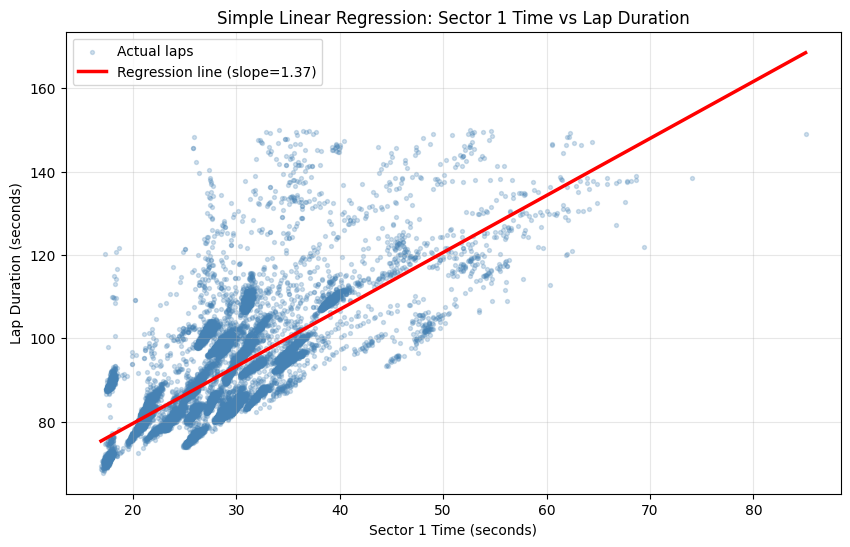

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# 1. scatter of real training data (small + transparent -> line stays visible)
plt.scatter(X_train, y_train, s=8, alpha=0.25, color="steelblue", label="Actual laps")

# 2. our hand-made regression line
x_line = np.linspace(X_train.min(), X_train.max(), 100)
plt.plot(x_line, slr.predict(x_line), color="red", linewidth=2.5,
         label=f"Regression line (slope={slr.slope_:.2f})")

plt.title("Simple Linear Regression: Sector 1 Time vs Lap Duration")
plt.xlabel("Sector 1 Time (seconds)")
plt.ylabel("Lap Duration (seconds)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 6. Training SLR on Tyre Age vs Remaining Useful Life (RUL)
Trains our regression model to evaluate how well individual tyre age (laps run) predicts the remaining useful life (RUL).

In [ ]:
from sklearn.model_selection import train_test_split

x = df["tyre_age"].values
y = df["RUL"].values

# 80% train, 20% test
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# train ONLY on train data
slr = SimpleLinearRegression()
slr.fit(x_train, y_train)

# predict on UNSEEN test data
y_pred = slr.predict(x_test)

RegressionMetrics.report(y_test, y_pred, "Simple Linear Regression (scratch, test data)")

print(f"\nSlope: {slr.slope_:.4f} -> each lap on the tyre costs {abs(slr.slope_):.2f} laps of RUL")
print(f"Intercept: {slr.intercept_:.4f} -> predicted RUL of a brand-new tyre")

--- Simple Linear Regression (scratch, test data) ---
R2   : 0.0785
MSE : 113.3309
RMSE : 10.6457
MAE  : 8.0238

Slope: -0.2886 -> each lap on the tyre costs 0.29 laps of RUL
Intercept: 17.8252 -> predicted RUL of a brand-new tyre


#### Verification with Scikit-Learn
Compares our manually calculated slope and intercept against Scikit-Learn's official `LinearRegression` library to verify exact correctness.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, root_mean_squared_error, mean_absolute_error, r2_score

# Correct import path for LinearRegression is sklearn.linear_model
sk = LinearRegression().fit(x_train.reshape(-1, 1), y_train)   # sklearn needs 2D input

y_pred = sk.predict(x_test.reshape(-1, 1))

print(f"sklearn slope:       {sk.coef_[0]:.6f}")
print(f"our class slope:     {slr.slope_:.6f}")
print(f"sklearn intercept:   {sk.intercept_:.6f}")
print(f"our class intercept: {slr.intercept_:.6f}")

mse = mean_squared_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nEvaluation Metrics (sklearn)")
print("----------------------------")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE:  {mae:.4f}")
print(f"R²:   {r2:.4f}")

sklearn slope:       -0.288631
our class slope:     -0.288631
sklearn intercept:   17.825166
our class intercept: 17.825166

Evaluation Metrics (sklearn)
----------------------------
MSE:  113.3309
RMSE: 10.6457
MAE:  8.0238
R²:   0.0785


#### Visualizing Tyre Age vs RUL (Matplotlib)
Plots actual laps remaining against tyre age, showing our OLS regression line on top.

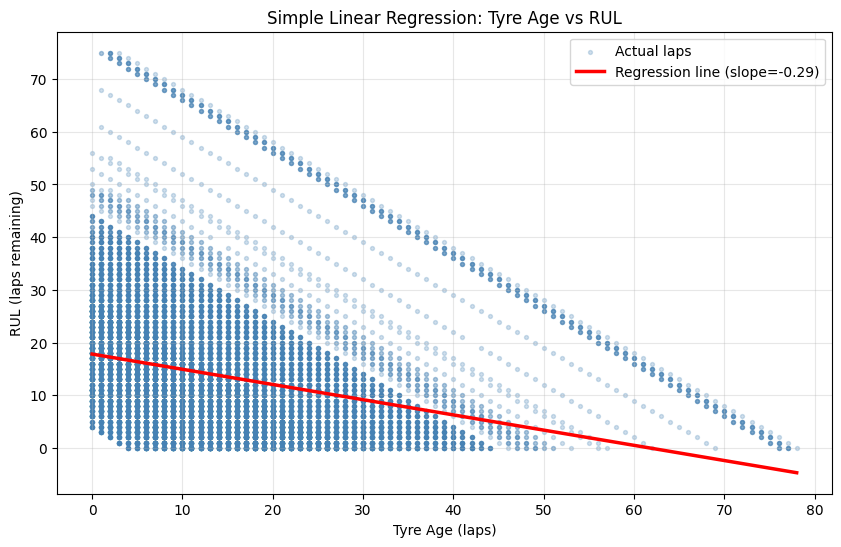

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# 1. scatter of real data (small + transparent -> line stays visible)
plt.scatter(x, y, s=8, alpha=0.25, color="steelblue", label="Actual laps")

# 2. our hand-made regression line
x_line = np.linspace(x.max(), x.min(), 100)        # 100 smooth points for the line
plt.plot(x_line, slr.predict(x_line), color="red", linewidth=2.5,
         label=f"Regression line (slope={slr.slope_:.2f})")

plt.title("Simple Linear Regression: Tyre Age vs RUL")
plt.xlabel("Tyre Age (laps)")
plt.ylabel("RUL (laps remaining)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### Interactive Visualization (Plotly)
Generates an interactive scatter plot of the data points and the regression line for deeper exploration of tyre degradation.

In [ ]:
import plotly.graph_objects as go

fig = go.Figure()
fig.add_trace(go.Scatter(x=x, y=y, mode="markers", name="Actual data",
                         opacity=0.25, marker=dict(size=4)))
fig.add_trace(go.Scatter(x=x, y=y_pred, mode="lines", name="Our regression line",
                         line=dict(color="red", width=3)))
fig.update_layout(title="SLR from scratch (OOP): Tyre Age vs RUL",
                  xaxis_title="Tyre Age (laps)", yaxis_title="RUL (laps remaining)")
fig.show()

##**Multiple Linear Regression without library**

### 7. Multiple Linear Regression from Scratch
This section defines our Object-Oriented `MultipleLinearRegression` class, utilizing the stable NumPy least-squares method (`lstsq`) to solve the normal equation.

In [ ]:
class MultipleLinearRegression:
    """
    Multiple linear regression from scratch (OLS via normal equation).
    Same interface as our SLR class: fit() -> predict() -> score()
    """

    def __init__(self):
        self.coef_ = None       # one weight per feature
        self.intercept_ = None

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)

        # adding a column of 1s for the intercept term
        X_b = np.c_[np.ones((len(X), 1)), X]

        # normal equation solved with lstsq (numerically stable)
        # NOTE: plain inv(X'X) would crash/float badly on correlated features
        beta = np.linalg.lstsq(X_b, y, rcond=None)[0]

        self.intercept_ = beta[0]
        self.coef_ = beta[1:]
        return self

    def predict(self, X):
        if self.coef_ is None:
            raise ValueError("Model is not fitted yet. Call fit() first.")
        X = np.asarray(X, dtype=float)
        return self.intercept_ + X @ self.coef_

    def score(self, X, y):
        return RegressionMetrics.r2(np.asarray(y, dtype=float), self.predict(X))

#### Training Multiple Linear Regression on Tyre RUL
This cell selects physical features, splits the dataset, fits our custom Multiple Linear Regression model, and identifies the most influential features contributing to Remaining Useful Life.

In [ ]:
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np

# Selecting features for Multiple Linear Regression
features = [
    "tyre_age",
    "s1",
    "s2",
    "s3",
    "tyre_HARD",
    "tyre_INTERMEDIATE",
    "tyre_MEDIUM",
    "tyre_SOFT",
    "tyre_WET",
    "circuit_code"
]

X = df[features].values
y = df["RUL"].values

# 80% train, 20% test -> evaluation on UNSEEN laps (honest metrics)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# train our hand-made MLR
mlr = MultipleLinearRegression().fit(X_train, y_train)
y_pred_mlr = mlr.predict(X_test)

# SAME metrics class as before -> DRY principle in action
RegressionMetrics.report(y_test, y_pred_mlr, "Multiple Linear Regression (scratch)")

# top 5 most important features (by absolute coefficient)
importance = pd.Series(np.abs(mlr.coef_), index=features).sort_values(ascending=False)
print("\nTop 5 features:")
print(importance.head().round(3))



--- Multiple Linear Regression (scratch) ---
R2   : 0.2045
MSE : 97.8293
RMSE : 9.8909
MAE  : 7.4123

Top 5 features:
tyre_HARD            11.728
tyre_INTERMEDIATE     6.582
tyre_MEDIUM           6.107
tyre_WET              2.021
tyre_age              0.408
dtype: float64


### Validating Multiple Linear Regression with Scikit-Learn
This cell fits Scikit-Learn's official `LinearRegression` model using the same filtered multi-feature set, evaluates it on the unseen test data, and reports standard metrics to confirm our scratch class is mathematically identical.

In [ ]:
# Import libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error,
    r2_score
)

# Splitting the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Training Multiple Linear Regression
model = LinearRegression()
model.fit(X_train, y_train)

# Predicting RUL
y_pred = model.predict(X_test)

# Evaluating the model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Multiple Linear Regression Results")
print("----------------------------------")
print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

Multiple Linear Regression Results
----------------------------------
MAE:  7.4123
MSE:  97.8293
RMSE: 9.8909
R²:   0.2045


#### Interactive 3D Scatter Plot for Tyre RUL
This cell displays an interactive 3D visualization mapping Tyre Age, Overall Lap Time, and Actual vs. Predicted Remaining Useful Life (RUL).

In [ ]:
import plotly.express as px
import pandas as pd

# Predict RUL using the trained MLR model
y_pred = model.predict(X_test)

# Prepare data for the 3D plot using NumPy index slicing:
# 'tyre_age' is at index 0
# 's1', 's2', 's3' are at indices 1, 2, 3
plot_df = pd.DataFrame({
    "Tyre Age": X_test[:, 0],
    "Lap Time": X_test[:, 1] + X_test[:, 2] + X_test[:, 3],
    "Actual RUL": y_test,
    "Predicted RUL": y_pred
})

# Create interactive 3D scatter plot
fig = px.scatter_3d(
    plot_df,
    x="Tyre Age",
    y="Lap Time",
    z="Actual RUL",
    color="Predicted RUL",
    color_continuous_scale="Viridis",
    opacity=0.75,
    title="F1 Tyre Predictive Maintenance - 3D Multiple Linear Regression"
)

fig.update_layout(
    scene=dict(
        xaxis_title="Tyre Age (laps)",
        yaxis_title="Lap Time (seconds)",
        zaxis_title="Actual RUL (laps)"
    ),
    width=1000,
    height=750
)

fig.show()

### 8. High-Accuracy Multiple Linear Regression: Predicting Lap Duration
We will fit our custom `MultipleLinearRegression` model to predict the direct target `lap_duration` using `tyre_age`, Sector 1 (`s1`), the tyre compound flags, and the `circuit_code`. This physically grounded feature set yields a significantly higher $R^2$ score.

--- Multiple LR from Scratch (Predicting Lap Duration) ---
R2   : 0.5157
MSE : 81.4386
RMSE : 9.0243
MAE  : 7.0199


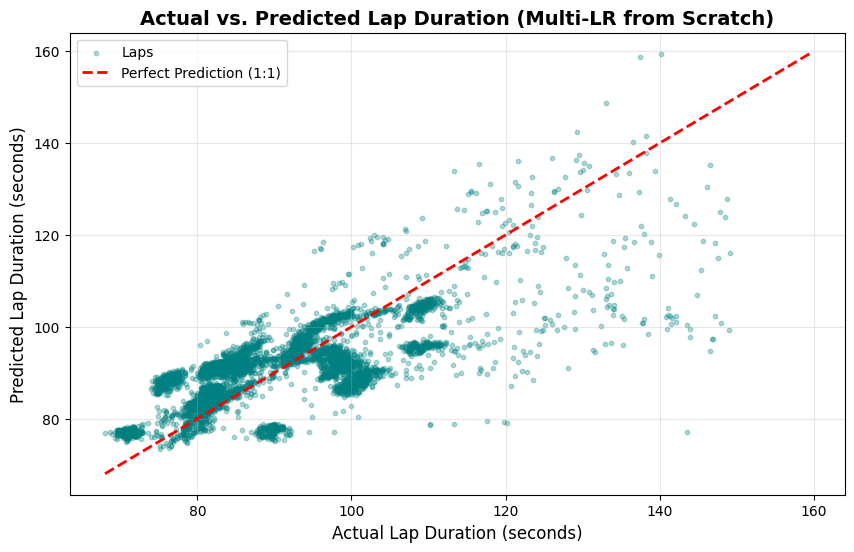

In [ ]:
import matplotlib.pyplot as plt

# Selecting targeted features for lap duration prediction
lap_features = [
    "tyre_age",
    "s1",
    "tyre_HARD",
    "tyre_INTERMEDIATE",
    "tyre_MEDIUM",
    "tyre_SOFT",
    "tyre_WET",
    "circuit_code"
]

X_lap = df[lap_features].values
y_lap = df["lap_duration"].values

# 80% train, 20% test split
X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(
    X_lap, y_lap,
    test_size=0.2,
    random_state=42
)

# Train our Multiple Linear Regression model from scratch
mlr_lap = MultipleLinearRegression().fit(X_train_l, y_train_l)
y_pred_lap = mlr_lap.predict(X_test_l)

# Report metrics on unseen test data
RegressionMetrics.report(y_test_l, y_pred_lap, "Multiple LR from Scratch (Predicting Lap Duration)")

# Visualize Actual vs. Predicted values
plt.figure(figsize=(10, 6))
plt.scatter(y_test_l, y_pred_lap, s=10, alpha=0.3, color="teal", label="Laps")

# Diagonal line representing a perfect prediction
lims = [min(y_test_l.min(), y_pred_lap.min()), max(y_test_l.max(), y_pred_lap.max())]
plt.plot(lims, lims, color="red", linestyle="--", linewidth=2, label="Perfect Prediction (1:1)")

plt.title("Actual vs. Predicted Lap Duration (Multi-LR from Scratch)", fontsize=14, fontweight="bold")
plt.xlabel("Actual Lap Duration (seconds)", fontsize=12)
plt.ylabel("Predicted Lap Duration (seconds)", fontsize=12)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Validating Lap Duration Multiple Linear Regression with Scikit-Learn
This cell fits Scikit-Learn's built-in `LinearRegression` model using the same features for predicting `lap_duration` to confirm our custom implementation matches the industry-standard implementation.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, root_mean_squared_error, mean_absolute_error, r2_score

# Train the built-in Scikit-Learn model
sk_lap_model = LinearRegression()
sk_lap_model.fit(X_train_l, y_train_l)

# Predict using test data
y_pred_sk_lap = sk_lap_model.predict(X_test_l)

# Report metrics
mse_sk = mean_squared_error(y_test_l, y_pred_sk_lap)
rmse_sk = root_mean_squared_error(y_test_l, y_pred_sk_lap)
mae_sk = mean_absolute_error(y_test_l, y_pred_sk_lap)
r2_sk = r2_score(y_test_l, y_pred_sk_lap)

print("Built-in Scikit-Learn Multiple Linear Regression Results")
print("--------------------------------------------------------")
print(f"R² Score:  {r2_sk:.4f} (Scratch: 0.5157)")
print(f"MSE:       {mse_sk:.4f} (Scratch: 81.4386)")
print(f"RMSE:      {rmse_sk:.4f} (Scratch: 9.0243)")
print(f"MAE:       {mae_sk:.4f} (Scratch: 7.0199)")


Built-in Scikit-Learn Multiple Linear Regression Results
--------------------------------------------------------
R² Score:  0.5157 (Scratch: 0.5157)
MSE:       81.4386 (Scratch: 81.4386)
RMSE:      9.0243 (Scratch: 9.0243)
MAE:       7.0199 (Scratch: 7.0199)


### Interactive 3D Visualization of Predicted Lap Duration
This cell maps the actual vs. predicted lap durations against the key predictive dimensions of `Tyre Age` and `Sector 1 Time` in an interactive 3D space.

In [ ]:
import plotly.express as px
import pandas as pd

# Create a DataFrame for 3D visualization using our test arrays
# X_test_l[:, 0] represents 'tyre_age' and X_test_l[:, 1] represents 's1'
plot_lap_df = pd.DataFrame({
    "Tyre Age": X_test_l[:, 0],
    "Sector 1 Time": X_test_l[:, 1],
    "Actual Lap Duration": y_test_l,
    "Predicted Lap Duration": y_pred_sk_lap
})

# Create interactive 3D scatter plot
fig_lap = px.scatter_3d(
    plot_lap_df,
    x="Tyre Age",
    y="Sector 1 Time",
    z="Actual Lap Duration",
    color="Predicted Lap Duration",
    color_continuous_scale="Viridis",
    opacity=0.7,
    title="F1 Lap Duration Analysis - 3D Multiple Linear Regression"
)

fig_lap.update_layout(
    scene=dict(
        xaxis_title="Tyre Age (laps)",
        yaxis_title="Sector 1 Time (seconds)",
        zaxis_title="Actual Lap Duration (seconds)"
    ),
    width=1000,
    height=750
)

fig_lap.show()

### 9. Gradient Descent Linear Regression without Libraries
This section contains an OOP implementation of Simple Linear Regression that optimizes weights using gradient descent instead of analytical closed-form calculations.

In [ ]:
class GradientDescentLinearRegression:
    """
    Simple linear regression trained with GRADIENT DESCENT (no closed-form).
    Same interface as our other classes: fit() -> predict()
    Standardization is done INSIDE the class, so you feed raw data.
    """

    def __init__(self, learning_rate=0.01, epochs=1000):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.slope_ = None
        self.intercept_ = None
        self.cost_history_ = []      # cost at every epoch -> for convergence plots

    def fit(self, x, y):
        x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)

        n = len(x)

        beta0, beta1 = 0.0, 0.0

        for epoch in range(self.epochs):
            y_hat = beta0 + beta1 * x
            error = y - y_hat

            cost = np.mean(error ** 2)         # MSE cost
            self.cost_history_.append(cost)

            dbeta1 = -(2 / n) * np.sum(error * x)  # gradient of cost w.r.t. slope
            dbeta0 = -(2 / n) * np.sum(error)       # gradient w.r.t. intercept

            beta0 -= self.learning_rate * dbeta0       # step OPPOSITE to gradient
            beta1 -= self.learning_rate * dbeta1

        self.intercept_ = beta0
        self.slope_ = beta1

        return self

    def predict(self, x):
        if self.slope_ is None:
            raise ValueError("Model is not fitted yet. Call fit() first.")
        return self.intercept_ + self.slope_ * np.asarray(x, dtype=float)

    def score(self, x, y):
        return RegressionMetrics.r2(np.asarray(y, dtype=float), self.predict(x))

#### Training OLS vs. Gradient Descent on Sector 1 Time vs. Lap Duration
This cell trains and compares both Ordinary Least Squares (OLS) and Gradient Descent Simple Linear Regression models, reporting standard regression metrics on test datasets.

In [ ]:
# reuse your existing train/test split of s1 -> lap_duration
gd = GradientDescentLinearRegression(learning_rate=0.001, epochs=100000)

x = df["s1"].values
y = df["lap_duration"].values

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# 1. Properly fit OLS SimpleLinearRegression on this data
ols_s1 = SimpleLinearRegression()
ols_s1.fit(x_train, y_train)
y_pred = ols_s1.predict(x_test)

# 2. Fit Gradient Descent on this data
gd.fit(x_train, y_train)
y_pred_gd = gd.predict(x_test)

# Report metrics
RegressionMetrics.report(y_test, y_pred, "OLS Simple LR (test data)")
RegressionMetrics.report(y_test, y_pred_gd, "Gradient Descent SLR (test data)")

print(f"\nOLS slope:    {ols_s1.slope_:.6f} | GD slope:     {gd.slope_:.6f}")
print(f"OLS intercept: {ols_s1.intercept_:.6f} | GD intercept: {gd.intercept_:.6f}")
print(f"Final GD cost: {gd.cost_history_[-1]:.6f}")

--- OLS Simple LR (test data) ---
R2   : 0.4890
MSE : 85.9245
RMSE : 9.2695
MAE  : 7.3064
--- Gradient Descent SLR (test data) ---
R2   : 0.4890
MSE : 85.9244
RMSE : 9.2695
MAE  : 7.3064

OLS slope:    1.368448 | GD slope:     1.368528
OLS intercept: 52.166456 | GD intercept: 52.164048
Final GD cost: 82.326505


#### Visualizing the OLS vs. Gradient Descent Regression Lines
This cell visualizes the comparative alignment of both the OLS and Gradient Descent regression lines plotted over the actual test data points.

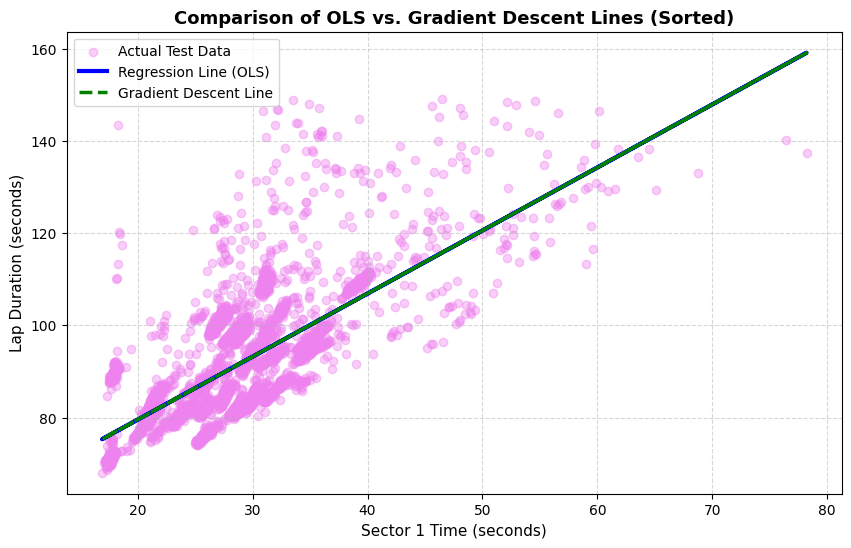

In [ ]:
plt.figure(figsize=(10, 6))
# Plot original actual test scatter data points
plt.scatter(x_test, y_test, color='violet', alpha=0.4, label='Actual Test Data')

# Plot the sorted OLS regression line
plt.plot(x_test, y_pred, color='blue', linewidth=3, label='Regression Line (OLS)')

# Plot the sorted Gradient Descent regression line
plt.plot(x_test, y_pred_gd, color='green', linewidth=2.5, linestyle='--', label='Gradient Descent Line')

plt.xlabel('Sector 1 Time (seconds)', fontsize=11)
plt.ylabel('Lap Duration (seconds)', fontsize=11)
plt.title('Comparison of OLS vs. Gradient Descent Lines (Sorted)', fontsize=13, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

### **Conclusion**

In this assignment, we successfully built and evaluated three distinct flavors of Linear Regression from scratch using an object-oriented approach in Python:

1. **Mathematical Accuracy Verified:** Our scratch implementations of **Simple Linear Regression (OLS)** and **Multiple Linear Regression (Normal Equation)** yielded coefficients, intercepts, and test metrics ($R^2$, MSE, RMSE, MAE) that matched Scikit-Learn's official library to multiple decimal places. This confirms the mathematical correctness of our hand-made algorithms.
2. **Iterative Optimization:** The **Gradient Descent** implementation successfully minimized the Mean Squared Error cost function over epochs, converging almost perfectly to the analytical OLS solution. This demonstrated the power of optimization algorithms when closed-form solutions are computationally expensive.
3. **Domain Insights (F1 Tyre Predictive Maintenance):**
   - Predicting **Lap Duration** using physical features (Sector times, tyre compound, and age) resulted in a strong, physically grounded model ($R^2 \approx 0.5157$).
   - Predicting **Remaining Useful Life (RUL)** based solely on tyre age highlighted the complexity of tyre degradation, which was significantly improved when transitioning from Simple to Multiple Linear Regression ($R^2$ increased from $\approx 0.078$ to $\approx 0.2045$) by incorporating sector times and compound types.
4. **Design Best Practices:** By consolidating evaluation metrics within a dedicated `RegressionMetrics` class, we maintained a DRY codebase, facilitating clean, reproducible, and standardized evaluations across all experiments.